# Decaimiento de muones: resumen del análisis

Lo más importante del análisis de las corridas de decaimientos (11/9 al 29/10 de 2026):
cómo se seleccionan los eventos, la vida media, y la comparación entre los muones que frenan
en el hierro y los que frenan en el centellador 3.

- El detalle completo, con todas las pruebas, está en `muones/informe/informe_decaimientos.pdf`.
- Las trazas no están en git: se bajan del *release* `muones-decaimientos-v1` (ver `muones/data/README.md`).
- Este notebook se corre desde `muones/analisis`. El código está en `decaimientos.py` y `dos_casos.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import decaimientos as dec
import dos_casos as dc

dc.estilo()                               # estilo de ESTILO_FIGURAS.md
plt.rcParams["figure.dpi"] = 75

## 1. Datos

Tres centelladores apilados (`u1`, `u2`, `u3`, de arriba hacia abajo) con una placa de hierro
entre el 2 y el 3. La placa DRS4 guarda 1024 muestras por canal (1,7 µs) cada vez que `u1`
baja de −100 mV. La primera vez que se corre, `indexar()` recorre todas las trazas (unos
2 minutos); después lee el índice ya hecho.

In [2]:
ev = dec.indexar()
tab = dec.tabla_eventos(ev)
print(f"{len(ev):,} eventos en {len(ev.runs)} corridas".replace(",", "."))

978.340 eventos en 9 corridas


## 2. Cómo se ve un decaimiento

Casi todos los eventos son muones que atraviesan: un solo pulso por centellador, cerca de
los 207 ns. Un muón que frena y decae deja además un **segundo pulso**, el del electrón. El
tiempo entre los dos, $\Delta t$, es lo que se mide.

En la figura: la curva clara es la traza cruda y la oscura, la suavizada (promedio de 10 ns);
los triángulos son los pulsos encontrados; la línea punteada marca la entrada del muón y la
llena, el pulso del electrón.

Evento 20260911 idx3 #1247: el electrón aparece 943 ns después, en u3


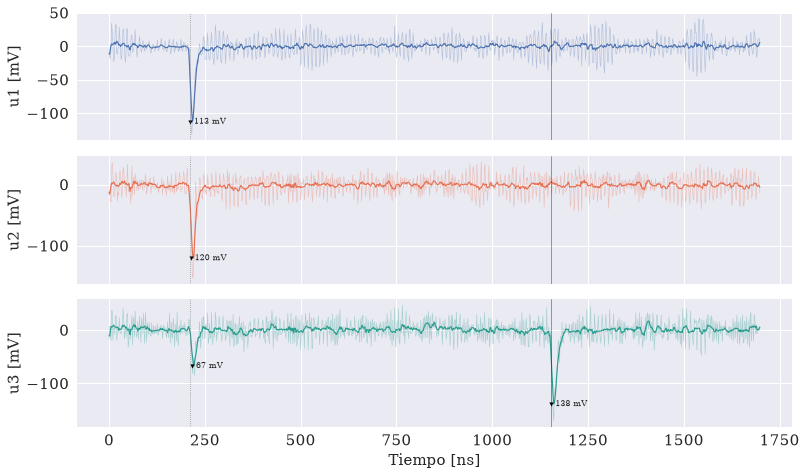

In [3]:
i = int(np.flatnonzero((tab["run"] == "run_20260911_135116") & (tab["idx"] == 3) & (tab["num"] == 1247))[0])
print(f"Evento {ev.etiqueta(i)}: el electrón aparece {tab['dt'].iloc[i]:.0f} ns después, en u{tab['canal_tardio'].iloc[i]}")
fig = dec.ver_evento(ev, i, tab)

## 3. Filtros

Se aplican uno sobre otro. Tres hacen todo el trabajo: que haya un segundo pulso, que tenga
al menos 60 mV y que $\Delta t$ esté entre 100 y 1400 ns.

In [4]:
P = dict(a_tardio_min=60, dt_rango=(100, 1400), ancho_rango=(10, 30))     # mV, ns, ns
filtros = dec.armar_filtros(tab, **P)
ACTIVOS = dc.FILTROS
sel = dec.combinar(filtros, ACTIVOS)
dec.flujo_de_cortes({n: filtros[n] for n in ACTIVOS})

,pasa solo,acumulado,% del anterior
corte,,,
traza limpia,977131,977131,99.9
entrada en u1,977604,976608,99.9
hay pulso tardio,4878,4664,0.5
amplitud tardio,2716,2690,57.7
dt en rango,4292,2421,90.0
ancho tardio,4007,2421,100.0
sin pulsos extra,978256,2421,100.0
sin pulsos previos,978271,2421,100.0


Doce de los eventos seleccionados, al azar. En cada panel se ve el pulso de entrada y, más
tarde, el del electrón (arriba de cada uno: corrida, archivo, número de evento, $\Delta t$ y
amplitud del segundo pulso).

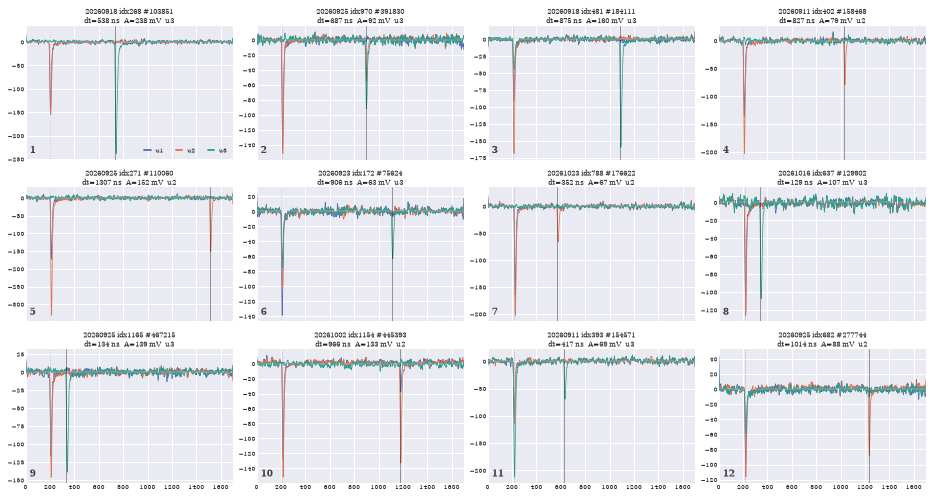

In [5]:
muestra = np.random.default_rng(1).permutation(np.flatnonzero(sel))[:12]
fig = dec.galeria(ev, muestra, tab, columnas=4, alto=2.2)

## 4. Vida media

Ajuste de máxima verosimilitud, sin agrupar en bins, de una exponencial normalizada en la
ventana de 100 a 1400 ns. El error es el intervalo donde el logaritmo de la verosimilitud
baja 1/2.

2421 decaimientos:  tau = 2070 ns  (+264 / −211)
Referencia: 2197 ns para el muón libre; unos 2100 ns esperados en plástico, por la captura de los mu−.


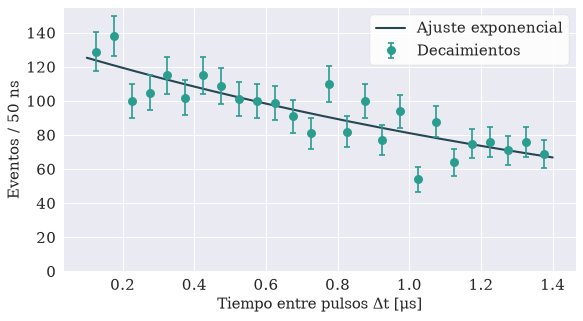

In [6]:
dt = tab.loc[sel, "dt"].to_numpy()
ajuste = dec.ajustar_vida_media(dt, P["dt_rango"])
print(f"{ajuste['n']} decaimientos:  tau = {ajuste['tau']:.0f} ns  (+{ajuste['err_mas']:.0f} / −{ajuste['err_menos']:.0f})")
print("Referencia: 2197 ns para el muón libre; unos 2100 ns esperados en plástico, por la captura de los mu−.")
fig = dec.graficar_ajuste(dt, ajuste, bins=26)

### ¿Depende de los cortes?

Se repite el ajuste cambiando la amplitud mínima del segundo pulso y el comienzo de la
ventana. Si la muestra son decaimientos, $\tau$ no debería moverse más que su error.

,eventos,tau [ns],−,+
ventana desde [ns],,,,
60,2542,1948,179,219
80,2491,1940,182,223
100,2421,2070,211,264
150,2292,2112,232,297
200,2154,2305,291,388
300,1949,2030,259,346


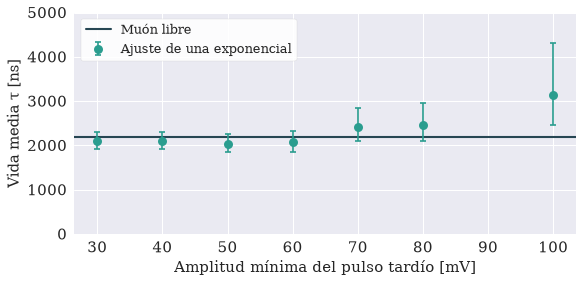

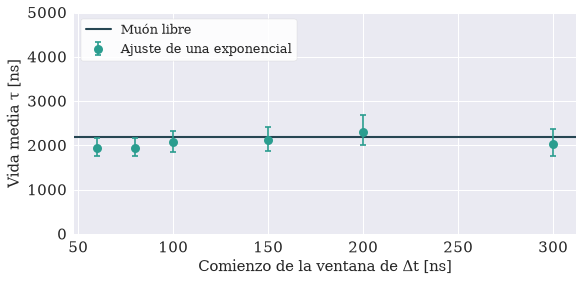

In [7]:
def tau_con(**cambios):
    f = dec.armar_filtros(tab, **{**P, **cambios})
    r = dec.ajustar_vida_media(tab.loc[dec.combinar(f, ACTIVOS), "dt"], cambios.get("dt_rango", P["dt_rango"]))
    return r

barridos = {"Amplitud mínima del pulso tardío [mV]": {a: tau_con(a_tardio_min=a) for a in (30, 40, 50, 60, 70, 80, 100)},
            r"Comienzo de la ventana de $\Delta t$ [ns]": {a: tau_con(dt_rango=(a, 1400)) for a in (60, 80, 100, 150, 200, 300)}}
for etiqueta, res_b in barridos.items():
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.axhline(dec.TAU_MU, color=dec.COLOR_AJUSTE, lw=2, zorder=2, label="Muón libre")
    ax.errorbar(list(res_b), [r["tau"] for r in res_b.values()],
                yerr=[[r["err_menos"] for r in res_b.values()], [r["err_mas"] for r in res_b.values()]],
                fmt="o", ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6, color=dec.COLOR_DATOS, zorder=3,
                label="Ajuste de una exponencial")
    ax.set_xlabel(etiqueta)
    ax.set_ylabel(r"Vida media $\tau$ [ns]")
    ax.set_ylim(0, 5000)
    ax.legend(loc="upper left", facecolor="white", framealpha=0.9, fontsize=12)
    fig.tight_layout()
pd.DataFrame({k: {"eventos": r["n"], "tau [ns]": round(r["tau"]), "−": round(r["err_menos"]), "+": round(r["err_mas"])}
              for k, r in barridos[r"Comienzo de la ventana de $\Delta t$ [ns]"].items()}).T.rename_axis("ventana desde [ns]")

Con la amplitud mínima entre 30 y 60 mV, $\tau$ no cambia. Con la ventana pasa algo distinto:
si empieza antes de 100 ns $\tau$ baja, y si empieza en 200 ns sube. Hay eventos de más a
$\Delta t$ corto (unos 47 ± 20 por debajo de 200 ns). Se descartó que sean pospulsos del
fotomultiplicador: aparecen igual en centelladores que no vieron pasar al muón (detalle en el
informe).

## 5. ¿Una exponencial o dos? Hierro contra plástico

Los $\mu^+$ decaen siempre con la vida media libre (2197 ns). Un $\mu^-$ frenado puede además
ser capturado por el núcleo, y entonces los que sí decaen lo hacen antes:
$1/\tau = 1/\tau_\text{decaimiento} + 1/\tau_\text{captura}$. En plástico casi no se nota
(2026 ns); en hierro la captura domina y la vida media baja a unos 206 ns.

Eso predice una componente rápida **solo donde hay hierro**. Se separan los decaimientos en
dos grupos y se ajusta cada uno con una exponencial y con la suma de dos (todo libre):

- **Grupo 1, frena en el hierro:** pulso de entrada en `u1` y `u2`, no en `u3`.
- **Grupo 2, cruza el hierro y frena en el centellador 3:** pulso de entrada en los tres.

Para esta comparación la ventana empieza en 60 ns, porque la componente rápida vive a
$\Delta t$ corto. La celda tarda alrededor de un minuto y medio: para cada grupo simula 200
muestras de una sola exponencial, para saber cuántas veces una mejora como la observada
aparece por azar.

In [8]:
grupos = dc.cargar_grupos()
res = {nombre: dc.analizar(x) for nombre, x in grupos.items()}

def columna(r):
    c1, g1, p1 = r["chi2_una"]
    c2, g2, p2 = r["chi2_dos"]
    it = r["intervalos"]
    return {"Eventos": r["n"],
            "UNA exponencial: tau": f"{r['tau']:.0f} ns ({r['tau_int'][0]:.0f} a {r['tau_int'][1]:.0f})",
            "UNA exponencial: chi2 / grados de libertad": f"{c1:.1f} / {g1}  (p = {p1:.2f})",
            "DOS exponenciales: tau rápida": dc.texto_intervalo(r["p2"][0], *it["tau_rapida"], 0),
            "DOS exponenciales: tau lenta": dc.texto_intervalo(r["p2"][1], *it["tau_lenta"], 1),
            "DOS exponenciales: fracción rápida": dc.texto_intervalo(r["p2"][2], *it["fraccion"], 2),
            "DOS exponenciales: chi2 / grados de libertad": f"{c2:.1f} / {g2}  (p = {p2:.2f})",
            "Mejora de la verosimilitud, 2·Δ(lnL)": f"{r['mejora']:.2f}",
            "p-valor de la mejora (simulado)": f"{r['p_mejora']:.2f}",
            "Con tau fijas en 206 y 2197 ns: fracción rápida": f"{100 * r['esperado_fraccion']:.1f} %",
            "Con tau fijas en 206 y 2197 ns: −lnL respecto del mejor": f"{r['esperado_dlnL']:+.2f}"}

pd.set_option("display.max_colwidth", 60)
pd.DataFrame({nombre: columna(r) for nombre, r in res.items()})

,Grupo 1: frena en el hierro,Grupo 2: cruza el hierro y frena en el centellador 3
Eventos,1888,654
UNA exponencial: tau,1817 ns (1638 a 2041),2454 ns (1963 a 3270)
UNA exponencial: chi2 / grados de libertad,17.3 / 18 (p = 0.50),14.6 / 18 (p = 0.69)
DOS exponenciales: tau rápida,42 ns (68 %: sin cota a 105 ns),203 ns (68 %: sin cota a sin cota)
DOS exponenciales: tau lenta,2025 ns (68 %: 1789 ns a 2277 ns),2875 ns (68 %: 2101 ns a sin cota)
DOS exponenciales: fracción rápida,1.5 % (68 %: 0.8 % a 3.0 %),2.2 % (68 %: sin cota a 37.5 %)
DOS exponenciales: chi2 / grados de libertad,15.0 / 16 (p = 0.52),14.3 / 16 (p = 0.57)
"Mejora de la verosimilitud, 2·Δ(lnL)",3.20,0.18
p-valor de la mejora (simulado),0.07,0.53
Con tau fijas en 206 y 2197 ns: fracción rápida,3.7 %,0.0 %


Grupo 1: frena en el hierro


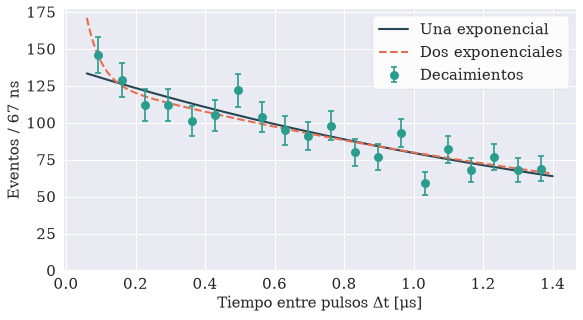

Grupo 2: cruza el hierro y frena en el centellador 3


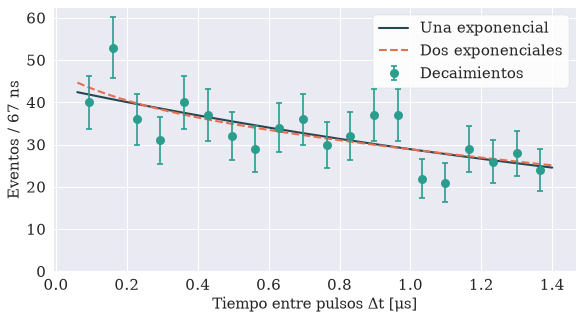

In [9]:
for nombre, x in grupos.items():
    print(nombre)
    fig = dc.figura(x, res[nombre])
    plt.show()

**Cómo leer la tabla.**

- Una sola exponencial ya ajusta bien en los dos grupos (χ² por grado de libertad cerca de 1).
- **Grupo 1 (hierro):** la segunda exponencial mejora el ajuste, con un p-valor de alrededor
  de 0,07. No llega al 0,05 habitual: es un indicio, no una detección.
- **Grupo 2 (centellador 3):** la segunda exponencial no aporta nada y sus parámetros quedan
  sin determinar ("sin cota" quiere decir que los datos no limitan ese valor).
- El χ² por grado de libertad no sirve para comparar los dos ajustes: al agregar dos
  parámetros se divide por menos, así que puede subir aunque el ajuste no empeore. Lo que se
  compara es cuánto mejora la verosimilitud.
- Dejando todo libre, los datos no alcanzan para medir las dos vidas medias (la rápida del
  grupo 1 da 42 ns). Pero con las vidas medias **fijas en los valores esperados** el ajuste
  es casi igual de bueno, y da una fracción rápida de 3,7 % en el hierro, contra 3,9 %
  predicho, y de 0 % en el centellador 3.

## 6. Conclusiones

- **Vida media:** $\tau = 2070$ ns (+264 / −211) con 2421 decaimientos, compatible con el muón
  libre (2197 ns) y con lo esperado en plástico (unos 2100 ns).
- **Robustez:** el valor no depende de los filtros ni de la amplitud mínima entre 30 y 60 mV.
- **Hierro:** los datos son compatibles con una componente de unos 206 ns de alrededor del
  4 % en los muones que frenan en el hierro, y con ninguna en los que frenan en el
  centellador 3, pero la evidencia es de alrededor de 2σ.
- **Límite principal:** la ventana de 1,3 µs es más corta que una vida media. Por eso el
  error de $\tau$ es de 11 % y no se pueden separar dos exponenciales. Una ventana de varias
  vidas medias es la mejora que más ayudaría.